In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from utils import load_root
ROOT = load_root()

from source.plots import p1 as plot_mod
from source.bunching import model as model_mod
from source.bunching.loader import load_counts


%load_ext autoreload
%autoreload 2

[utils] Project root loaded successfully: /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2


In [2]:
datapath = ROOT / 'data/bunch_counts_wages.csv'
ROOT

PosixPath('/home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2')

In [3]:
wage_df = pd.read_csv(datapath, sep=';')
desc = wage_df.describe().T          # .T = variables en filas
desc['miss'] = wage_df.isna().sum()
desc

,count,mean,std,min,25%,50%,75%,max,miss
group_0,23926.0,6.727287e+07,4.224053e+07,0.0,31800000.0,63300000.0,98400000.0,159900000.0,0
year,23926.0,2.015273e+03,5.235702e+00,2005.0,2011.0,2016.0,2020.0,2023.0,0
NREG,23926.0,1.129128e+03,2.563783e+03,11.0,34.0,135.0,754.0,17707.0,0


### Cutoff Shifting 

saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p1/p1_cutoff_shift_grid.pdf


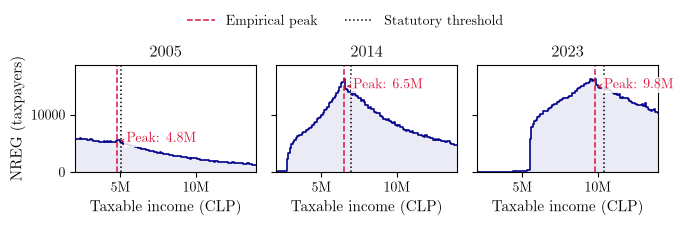

In [4]:
sample_years = [2005, 2014, 2023]
thr_df = pd.read_csv(ROOT / "data/threshold.csv").set_index("year")

panels_data = []
for y in sample_years:
    df_y = wage_df[wage_df["year"] == y].sort_values("group_0")
    zy = df_y["group_0"].to_numpy(float)
    cy = df_y["NREG"].to_numpy(float)
    zs = float(thr_df.loc[y, "threshold_clp"])

    # Pico empírico en la vecindad del umbral [0.75 * zs, 1.05 * zs]
    near = (zy >= 0.75 * zs) & (zy <= 1.05 * zs)
    peak_z = float(zy[np.flatnonzero(near)[np.argmax(cy[near])]])

    panels_data.append({
        "year": y,
        "z": zy,
        "c": cy,
        "peak_z": peak_z,
        "threshold_z": zs,
    })

fig, axes = plt.subplots(1, 3, figsize=(7, 2.0), sharey=True)
plot_mod.plot_cutoff_shift_grid(panels_data, fig, axes, xlim=(2e6, 14e6))
plot_mod.save_fig(plot_mod.FIGURES_DIR / "p1/p1_cutoff_shift_grid.pdf", fig)
plt.show()

saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p1/p1_observed_2023.pdf


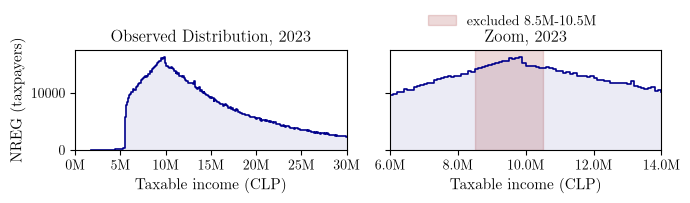

In [5]:
year = 2023
fig, axes = plt.subplots(1, 2, figsize=(7, 2.5), sharey=True)
fig, axes = plot_mod.plot_observed_distribution(wage_df, fig, axes=axes, year=year)
plot_mod.save_fig(plot_mod.FIGURES_DIR / f"p1/p1_observed_{year}.pdf", fig)
plt.show()

## The neighbourhood of the kink

The pile-up is not a single-bin artefact. The chart below zooms on $\pm 5$ bins around the peak and draws two horizontal segments: the average count of the five bins that end at the peak and the average count of the five bins that start immediately above it. If the kink is real, the second segment lies below the first and the gap does not close in the following bins.

saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p1/p1_kink_neighbourhood.pdf


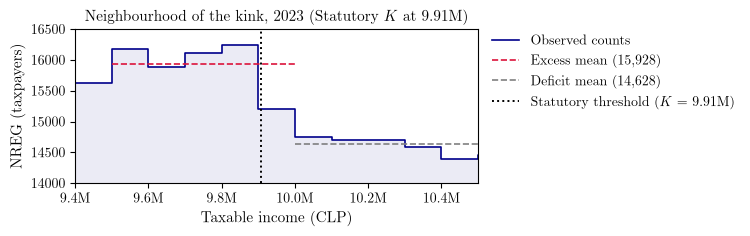

Statutory threshold (K): 9.91M
excess block (9.5-9.9M): mean=15928
deficit block (10.0-10.4M): mean=14628
drop=1300 (8.2%)


In [6]:
year = 2023
Z_STAR = 9_907_434  # Umbral estatutario de los autores (K)
Z_L, Z_R = 8.5e6, 10.5e6
Z_LOW, Z_HIGH = 6.5e6, 20e6

z, c = load_counts(datapath, year=year)

fig, ax = plt.subplots(figsize=(5.2, 2))
ax, mean_below, mean_above, r_below, r_above = plot_mod.plot_kink_neighbourhood(
    z, c, ax, Z_STAR, n_bins=5
)
ax.set_title(f"Neighbourhood of the kink, {year} (Statutory $K$ at {Z_STAR/1e6:.2f}M)", fontsize=11)
ax.set_ylim(14000, 16500)
plot_mod.save_fig(plot_mod.FIGURES_DIR / "p1/p1_kink_neighbourhood.pdf", fig)
plt.show()

print(f"Statutory threshold (K): {Z_STAR/1e6:.2f}M")
print(f"excess block ({r_below[0]/1e6:.1f}-{r_below[1]/1e6:.1f}M): mean={mean_below:.0f}")
print(f"deficit block ({r_above[0]/1e6:.1f}-{r_above[1]/1e6:.1f}M): mean={mean_above:.0f}")
print(f"drop={mean_below - mean_above:.0f} ({100*(1 - mean_above/mean_below):.1f}%)")

### Chetty fix effect

Con ajuste Chetty:    B = 16,219 | eps = 0.2798
Sin ajuste (naive):   B = 19,022 | eps = 0.3314
saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p1/p1_chetty_comparison.pdf


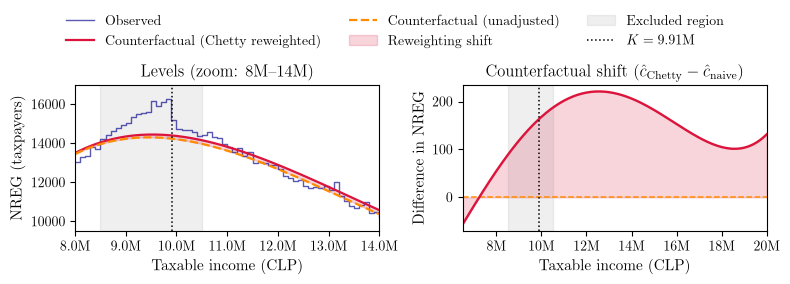

In [7]:
year = 2023
Z_STAR = 9_907_434
Z_L, Z_R = 8.5e6, 10.5e6
Z_LOW, Z_HIGH = 6.5e6, 20e6

z, c = load_counts(datapath, year=year)

c_hat_chetty = model_mod.counterfactual(z, c, Z_LOW, Z_HIGH, Z_L, Z_R, degree=4, chetty=True)
c_hat_naive = model_mod.counterfactual(z, c, Z_LOW, Z_HIGH, Z_L, Z_R, degree=4, chetty=False)

# Comparar impacto numérico en B y epsilon
m_chetty = model_mod.excess_mass(z, c, c_hat_chetty, Z_L, Z_R)
m_naive = model_mod.excess_mass(z, c, c_hat_naive, Z_L, Z_R)
eps_chetty = model_mod.elasticity(m_chetty["b"], Z_STAR)
eps_naive = model_mod.elasticity(m_naive["b"], Z_STAR)

print(f"Con ajuste Chetty:    B = {m_chetty['B']:,.0f} | eps = {eps_chetty:.4f}")
print(f"Sin ajuste (naive):   B = {m_naive['B']:,.0f} | eps = {eps_naive:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 2.4))
plot_mod.plot_chetty_comparison(z, c, c_hat_chetty, c_hat_naive, Z_STAR, Z_L, Z_R, fig, axes)
plot_mod.save_fig(plot_mod.FIGURES_DIR / "p1/p1_chetty_comparison.pdf", fig)
plt.show()

In [8]:
year = 2023
Z_STAR, Z_L, Z_R = 9_907_434, 8.5e6, 10.5e6
Z_LOW, Z_HIGH = 6.5e6, 20e6  # estimation window

z, c = load_counts(ROOT / "data/bunch_counts_wages.csv", year=year)
fit = model_mod.estimate(z, c, Z_STAR, Z_LOW, Z_HIGH, Z_L, Z_R, degree=4, normalize='mean')
print(f"B={fit['B']:.0f}  b={fit['b']:.0f}  eps={fit['epsilon']:.4f}")

B=16219  b=113160  eps=0.2798


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p1/p1_counterfactual_2023.pdf


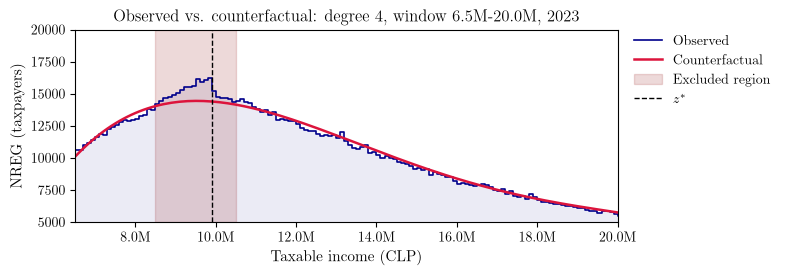

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.5))
ax = plot_mod.plot_counterfactual(z, c, fit["c_hat"], ax, z_star=Z_STAR, z_L=Z_L, z_R=Z_R, xlim=(Z_LOW, Z_HIGH))
ax.set_title(f"Observed vs. counterfactual: degree 4, window {Z_LOW/1e6:.1f}M-{Z_HIGH/1e6:.1f}M, {year}")
ax.set_ylim(5000, 20000)
plot_mod.save_fig(plot_mod.FIGURES_DIR / f"p1/p1_counterfactual_{year}.pdf", fig)
plt.show()

In [10]:
rows = []
for z_star in [9.6e6, 9.8e6, 10.0e6, 10.4e6]:
    for norm in ["mean", "kink"]:
        r = model_mod.estimate(z, c, z_star, Z_LOW, Z_HIGH, Z_L, Z_R, degree=4, normalize=norm)
        rows.append({"z_star_M": z_star / 1e6, "normalize": norm,
                     "B": round(r["B"], 1), "b": round(r["b"]), "epsilon": round(r["epsilon"], 4)})

table = pd.DataFrame(rows)
(ROOT / "output/tables").mkdir(parents=True, exist_ok=True)
table.to_csv(ROOT / "output/tables/p1_iii_elasticity.csv", index=False)
table

,z_star_M,normalize,B,b,epsilon
0,9.6,mean,16219.3,113160,0.2888
1,9.6,kink,16219.3,115456,0.2946
2,9.8,mean,16219.3,113160,0.2829
3,9.8,kink,16219.3,115456,0.2886
4,10.0,mean,16219.3,113160,0.2772
5,10.0,kink,16219.3,115456,0.2828
6,10.4,mean,16219.3,113160,0.2665
7,10.4,kink,16219.3,115456,0.2720


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p1/p1_elasticity_sensitivity.pdf


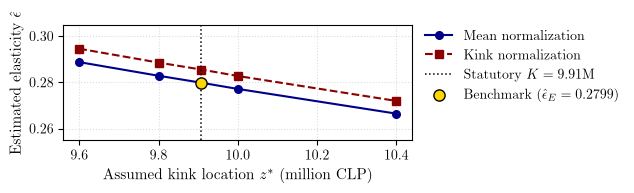

In [11]:
rows_k = pd.DataFrame([
    {"z_star_M": 9_907_434 / 1e6, "normalize": "mean", "B": 16219.3, "b": 113160, "epsilon": 0.2799},
    {"z_star_M": 9_907_434 / 1e6, "normalize": "kink", "B": 16219.3, "b": 115456, "epsilon": 0.2856},
])
df_plot = pd.concat([table, rows_k], ignore_index=True).drop_duplicates(subset=["z_star_M", "normalize"])

fig, ax = plt.subplots(figsize=(4.5, 1.5))
plot_mod.plot_elasticity_sensitivity(df_plot, ax)
plot_mod.save_fig(plot_mod.FIGURES_DIR / "p1/p1_elasticity_sensitivity.pdf", fig)
plt.show()

### Sensitivity

In [12]:
from source.bunching.loader import resample_counts

BIN_FACTORS = {1: 100_000, 2: 200_000, 3: 300_000, 5: 500_000}
WINDOWS = [(6.5e6, 20e6), (5e6, 20e6), (6.5e6, 30e6), (5e6, 30e6)]

rows = []
for factor, dz in BIN_FACTORS.items():
    zb, cb = resample_counts(z, c, factor)
    z_L, z_R = zb[zb >= 8.5e6].min(), zb[zb <= 10.5e6].max()
    for z_low, z_high in WINDOWS:
        r = model_mod.estimate(zb, cb, Z_STAR, z_low, z_high, z_L, z_R, degree=4)
        rows.append({"bin_k": dz // 1000, "window": f"{z_low/1e6:.1f}-{z_high/1e6:.1f}M",
                     "excl_bins": r["b"] and int(((zb >= z_L) & (zb <= z_R)).sum()),
                     "B": round(r["B"], 1), "b": round(r["b"]), "epsilon": round(r["epsilon"], 4)})

sens = pd.DataFrame(rows)
sens.to_csv(ROOT / "output/tables/p1_iv_sensitivity.csv", index=False)
sens

,bin_k,window,excl_bins,B,b,epsilon
0,100,6.5-20.0M,21,16219.3,113160,0.2798
1,100,5.0-20.0M,21,7596.5,51452,0.1272
2,100,6.5-30.0M,21,29175.4,213188,0.5271
3,100,5.0-30.0M,21,23877.4,171162,0.4232
4,200,6.5-20.0M,10,15048.3,104491,0.2584
5,200,5.0-20.0M,10,8236.9,55730,0.1378
6,200,6.5-30.0M,10,27219.4,198313,0.4903
7,200,5.0-30.0M,10,22721.2,162581,0.4020
8,300,6.5-20.0M,7,14938.3,103701,0.2564
9,300,5.0-20.0M,7,9202.2,62499,0.1545


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p1/p1_iv_sensitivity.pdf


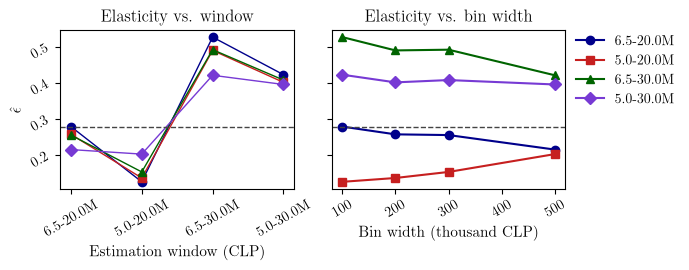

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), sharey=True)
plot_mod.plot_sensitivity(sens, axes)
fig.tight_layout()
plot_mod.save_fig(plot_mod.FIGURES_DIR / "p1/p1_iv_sensitivity.pdf", fig)
plt.show()

## Pooling across years

The exemption threshold is nominal: it changes every year. Stacking the raw counts would put the 2005 and the 2023 pile-ups in different bins and the mixture would smooth the bunching away. Each year's income is therefore divided by its own exempt threshold (`data/threshold.csv`), so that the kink maps to $z=1$ in every year, and the counts are then pooled on a common grid of 0.01 threshold units.

In [14]:
from source.bunching.loader import pool_counts

THRESHOLD_PATH = ROOT / "data/threshold.csv"
years = sorted(wage_df["year"].unique())
counts = {y: load_counts(datapath, year=y) for y in years}

thr = pd.read_csv(THRESHOLD_PATH).set_index("year")["threshold_clp"].to_dict()
scale = {y: float(thr[y]) for y in years}

Z_POOL, C_POOL = pool_counts(counts, scale, width=0.01)

Z_STAR_P = 1.0
Z_LO_P, Z_HI_P = 0.625, 1.923   # 6.5M and 20M relative to the 2023 threshold
Z_L_P, Z_R_P = 0.817, 1.009     # 8.5M and 10.5M relative to the 2023 threshold

print(f"years: {years[0]}-{years[-1]} ({len(years)}) | bins: {len(Z_POOL)}")
print(f"z*={Z_STAR_P} window=({Z_LO_P}, {Z_HI_P}) excluded=({Z_L_P}, {Z_R_P})")

years: 2005-2023 (19) | bins: 2382
z*=1.0 window=(0.625, 1.923) excluded=(0.817, 1.009)


## Is the statutory threshold the right alignment?

Pooling only preserves the pile-up if every year's bunching mass lands in the same bin after dividing by the threshold. If taxpayers bunch systematically *below* the statutory threshold, and that gap changes over time, the years' spikes fall in different bins and the pooled density flattens even though each year shows clear bunching.

This diagnostic measures the gap year by year. For each year we look for the empirical pile-up within a neighbourhood of the statutory threshold ($0.75$ to $1.05$ times the threshold), using the local mode — the bin with the largest count inside that neighbourhood — which is robust because the pile-up dominates the monotone decline. We report the ratio `peak / threshold`. If that ratio is roughly constant across years, normalising by the threshold aligns the years and the pooled estimate is meaningful; if it drifts, the pooled bunching is partly an artefact of the mixture and the series should be aligned on the empirical peak instead.

In [15]:
import numpy as np

rows = []
for y in years:
    zy, cy = counts[y]
    zs = float(thr[y])
    near = (zy >= 0.75 * zs) & (zy <= 1.05 * zs)
    j = np.flatnonzero(near)[np.argmax(cy[near])]
    rows.append({"year": y, "threshold_M": zs / 1e6, "peak_M": zy[j] / 1e6,
                 "ratio": zy[j] / zs})

align = pd.DataFrame(rows)
sd = align["ratio"].std()
print(f"ratio peak/threshold: mean={align['ratio'].mean():.4f} sd={sd:.4f} "
      f"min={align['ratio'].min():.3f} max={align['ratio'].max():.3f}")
print(f"sd in bins of 0.01 threshold units: {sd / 0.01:.1f}")
align

ratio peak/threshold: mean=0.9486 sd=0.0305 min=0.868 max=1.009
sd in bins of 0.01 threshold units: 3.1


,year,threshold_M,peak_M,ratio
0,2005,5.028480,4.8,0.954563
1,2006,5.156460,5.0,0.969657
2,2007,5.547078,5.1,0.919403
3,2008,6.024942,5.5,0.912872
4,2009,5.948928,6.0,1.008585
5,2010,6.078342,5.9,0.970659
6,2011,6.304674,6.0,0.951675
7,2012,6.474600,6.3,0.973033
8,2013,6.603012,6.4,0.969255
9,2014,6.975072,6.5,0.931890


pooled B=206823 b=0.0137 eps=0.3356
saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p1/p1_pooled_bunching.pdf


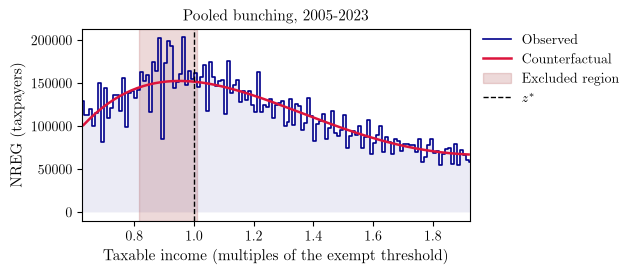

In [19]:
fit_pool = model_mod.estimate(Z_POOL, C_POOL, Z_STAR_P, Z_LO_P, Z_HI_P, Z_L_P, Z_R_P, degree=4)
print(f"pooled B={fit_pool['B']:.0f} b={fit_pool['b']:.4f} eps={fit_pool['epsilon']:.4f}")

fig, ax = plt.subplots(figsize=(5, 2.5))
plot_mod.plot_pooled_bunching(Z_POOL, C_POOL, fit_pool["c_hat"], ax,
                              z_star=Z_STAR_P, z_L=Z_L_P, z_R=Z_R_P, xlim=(Z_LO_P, Z_HI_P))
ax.set_title(f"Pooled bunching, {years[0]}-{years[-1]}", fontsize=11)
plot_mod.save_fig(plot_mod.FIGURES_DIR / "p1/p1_pooled_bunching.pdf", fig)
plt.show()

saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p1/p1_peak_ratio_trend.pdf


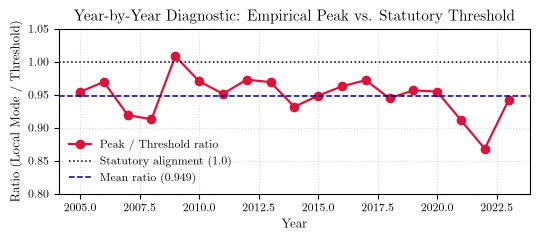

In [25]:
fig, ax = plt.subplots(figsize=(5.5, 2.5))

# Graficar la evolución del ratio año a año
ax.plot(align["year"], align["ratio"], marker="o", color="crimson", lw=1.6, label="Peak / Threshold ratio")
ax.axhline(1.0, color="black", ls=":", lw=1.1, label="Statutory alignment (1.0)")
ax.axhline(align["ratio"].mean(), color="darkblue", ls="--", lw=1.1, 
           label=f"Mean ratio ({align['ratio'].mean():.3f})")

ax.set_title("Year-by-Year Diagnostic: Empirical Peak vs. Statutory Threshold", fontsize=11)
ax.set_xlabel("Year", fontsize=9)
ax.set_ylabel("Ratio (Local Mode / Threshold)", fontsize=9)
ax.set_ylim(0.80, 1.05)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="lower left", frameon=False, fontsize=8)
ax.tick_params(labelsize=8)

fig.tight_layout()
plot_mod.save_fig(plot_mod.FIGURES_DIR / "p1/p1_peak_ratio_trend.pdf", fig)
plt.show()

## Alignment on the empirical peak

The diagnostic shows the pile-up sits about 5% below the statutory threshold, and that gap is not constant (sd = 0.03, i.e. three 0.01-width bins). Statutory normalisation therefore scatters the spike. As a robustness check, the series is re-pooled with each year's local mode as the scale, so that the pile-up lands at $z=1$ by construction. The estimation window and the excluded region are kept unchanged in normalised units. `spike/counterfactual` at $z=1$ is reported for both alignments: it is the ratio of the pooled count to the fitted counterfactual in the bunching bin, so a higher value means a sharper, more visible spike.

statutory : B=206823 eps=0.3356 spike=1.063
peak-align: B=166065 eps=0.2899 spike=1.534
saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p1/p1_pooled_aligned.pdf


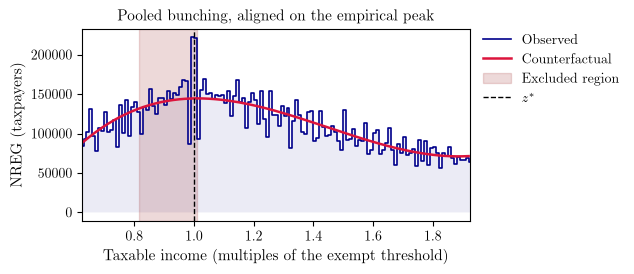

In [24]:
peak_clp = {}
for y in years:
    zy, cy = counts[y]
    zs = float(thr[y])
    near = (zy >= 0.75 * zs) & (zy <= 1.05 * zs)
    peak_clp[y] = zy[np.flatnonzero(near)[np.argmax(cy[near])]]

Z_ALIGN, C_ALIGN = pool_counts(counts, peak_clp, width=0.01)
fit_align = model_mod.estimate(Z_ALIGN, C_ALIGN, Z_STAR_P, Z_LO_P, Z_HI_P, Z_L_P, Z_R_P, degree=4)

def spike_ratio(z, c, c_hat, z0=1.0):
    j = np.argmin(np.abs(z - z0))
    return c[j] / c_hat[j]

print(f"statutory : B={fit_pool['B']:.0f} eps={fit_pool['epsilon']:.4f} spike={spike_ratio(Z_POOL, C_POOL, fit_pool['c_hat']):.3f}")
print(f"peak-align: B={fit_align['B']:.0f} eps={fit_align['epsilon']:.4f} spike={spike_ratio(Z_ALIGN, C_ALIGN, fit_align['c_hat']):.3f}")

fig, ax = plt.subplots(figsize=(5, 2.5))
plot_mod.plot_pooled_bunching(Z_ALIGN, C_ALIGN, fit_align["c_hat"], ax,
                              z_star=Z_STAR_P, z_L=Z_L_P, z_R=Z_R_P, xlim=(Z_LO_P, Z_HI_P))
ax.set_title("Pooled bunching, aligned on the empirical peak", fontsize=11)
plot_mod.save_fig(plot_mod.FIGURES_DIR / "p1/p1_pooled_aligned.pdf", fig)
plt.show()